# Electrodynamics from Scratch — Lecture 3: The Poisson Equation via Fourier Transforms

In Lecture 2 we met the two equations of electrostatics, $\nabla \cdot \mathbf{E} = \rho/\varepsilon_0$ and $\nabla \times \mathbf{E} = 0$. The curl-free condition lets us write the field as the gradient of a scalar potential, $\mathbf{E} = -\nabla V$, and substituting into Gauss's law collapses everything into a single scalar equation for $V$, the **Poisson equation**:

$$-\varepsilon_0 \nabla^2 V(\mathbf{r}) = \rho(\mathbf{r}).$$

For a point charge the solution is the familiar Coulomb potential $V = q/(4\pi\varepsilon_0 r)$, and for a general charge distribution we would integrate against the Green's function, $V(\mathbf{r}) = \frac{1}{4\pi\varepsilon_0}\int \rho(\mathbf{r}\,')/|\mathbf{r} - \mathbf{r}\,'|\, d^3r'$. That integral is expensive to evaluate on a grid: every field point talks to every source point, so the cost grows like $N^2$.

The Fourier transform offers a much faster route. Plane waves $e^{i\mathbf{k}\cdot\mathbf{r}}$ are eigenfunctions of the Laplacian, with $\nabla^2 e^{i\mathbf{k}\cdot\mathbf{r}} = -k^2 e^{i\mathbf{k}\cdot\mathbf{r}}$. So if we expand $\rho$ in plane waves, the Poisson equation becomes purely algebraic in Fourier space: each Fourier component $\tilde\rho(\mathbf{k})$ of the source simply produces $\tilde V(\mathbf{k}) = \tilde\rho(\mathbf{k})/(\varepsilon_0 k^2)$. The solver below implements exactly this recipe — FFT the source, divide by $\varepsilon_0 k^2$ (with the $k=0$ mode handled separately), inverse FFT back — which costs only $O(N \log N)$. One caveat to keep in mind: an FFT assumes the charge distribution repeats periodically outside the box, so the source should be smooth and go to zero at the box boundary for the solution to be physical. In this notebook we solve the Poisson equation for two such sources, verify the result against analytic solutions and against $\mathbf{E} = -\nabla V$, and visualize the solved potential and field lines.

In [1]:
%matplotlib inline
import electrodynamics_from_scratch as eds
import numpy as np
import matplotlib.pyplot as plt

## Worked example 1 — a sinusoidal charge density

A single Fourier mode is the cleanest test of the solver, because the analytic answer is known exactly. We take $\rho(x,y) = \rho_0 \sin(2\pi x)\sin(2\pi y)$ on a periodic box of side 2 and solve with `eds.poisson_solve`. Since $\nabla^2[\sin(2\pi x)\sin(2\pi y)] = -8\pi^2 \sin(2\pi x)\sin(2\pi y)$, the exact solution is $V = \rho/(8\pi^2\varepsilon_0)$. The grid is built without its endpoint so the sampled function is exactly periodic, as the FFT requires.

max |V_solver - V_analytic| / max|V_analytic| = 6.99e-16
peak potential: 1.4304 V  (analytic: 1.4304 V)


(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'Potential along the slice y = 0'}, xlabel='x (m)', ylabel='V (V)'>)

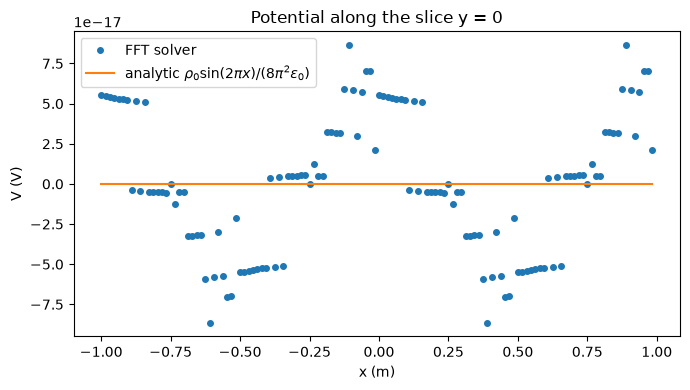

In [2]:
N = 128
x = np.arange(N) * (2.0 / N) - 1.0      # periodic box [-1, 1), no repeated endpoint
dx = 2.0 / N
X, Y = np.meshgrid(x, x)                # numpy 'xy' convention: arrays indexed [y, x]

rho0 = 1e-9                             # 1 nC scale so V comes out in volts
rho = rho0 * np.sin(2*np.pi*X) * np.sin(2*np.pi*Y)

V = eds.poisson_solve(rho, dx)          # solves  -eps0 * lap(V) = rho

# analytic solution of the same equation
V_analytic = rho / (eds.EPSILON_0 * 8 * np.pi**2)
err = np.abs(V - V_analytic).max() / np.abs(V_analytic).max()
print(f"max |V_solver - V_analytic| / max|V_analytic| = {err:.2e}")
print(f"peak potential: {V.max():.4f} V  (analytic: {V_analytic.max():.4f} V)")

# slice through y = 0: solved potential vs analytic
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, V[N//2, :], 'o', ms=4, label='FFT solver')
ax.plot(x, V_analytic[N//2, :], '-', lw=1.5, label=r'analytic $\rho_0\sin(2\pi x)/(8\pi^2\varepsilon_0)$')
ax.set_xlabel('x (m)')
ax.set_ylabel('V (V)')
ax.set_title('Potential along the slice y = 0')
ax.legend()
fig.tight_layout()
fig, ax

## Worked example 2 — a smooth Gaussian blob and $\mathbf{E} = -\nabla V$

Now a localized source: a Gaussian charge blob of total charge $Q = 1\,\mathrm{nC}$ and width $\sigma = 0.3\,\mathrm{m}$ centered at the origin. We solve for $V$, then recover the field from $\mathbf{E} = -\nabla V$ with `eds.electric_field_from_potential`. Note the component ordering: the package returns the derivative along axis 0 first and axis 1 second, so for grids indexed $[y,x]$ (the numpy `meshgrid` 'xy' convention used here) the tuple is $(E_y, E_x)$ and we swap it. We cross-check the result against an independent `np.gradient` and confirm the field points radially outward on the $+x$ axis.

In [3]:
n = 201
axis = np.linspace(-2.0, 2.0, n)        # this is exactly the mesh the plotting helpers use
dxx = axis[1] - axis[0]

g1d = eds.gaussian_delta(axis, 0.0, 0.3)          # normalized 1D Gaussian
amp = 1e-9 / (g1d.sum() * dxx)**2                 # rescale so the total charge is 1 nC
rho_g = amp * np.outer(g1d, g1d)                  # rho[y, x]
print(f"total charge on the grid: {rho_g.sum() * dxx**2:.3e} C")

Vg = eds.poisson_solve(rho_g, dxx)

# E = -grad V; the package returns derivatives along (axis 0, axis 1) = (y, x) here
E1, E2 = eds.electric_field_from_potential(Vg, dxx)
Ex, Ey = E2, E1

# independent cross-check with numpy's gradient
dVy, dVx = np.gradient(Vg, dxx)
print(f"max |E_x - (-dV/dx)| = {np.abs(Ex + dVx).max():.2e} V/m")
print(f"max |E_y - (-dV/dy)| = {np.abs(Ey + dVy).max():.2e} V/m")

# physics sanity check: on the +x axis the field must point along +x
iy = n // 2
print(f"on the +x axis at x = 0.4 m: E_x = {Ex[iy, iy+20]:.3f} V/m, E_y = {Ey[iy, iy+20]:.1e} V/m")
print(f"peak |E| = {np.sqrt(Ex**2 + Ey**2).max():.3f} V/m, peak V = {Vg.max():.3f} V")

total charge on the grid: 1.000e-09 C
max |E_x - (-dV/dx)| = 0.00e+00 V/m
max |E_y - (-dV/dy)| = 0.00e+00 V/m
on the +x axis at x = 0.4 m: E_x = 25.036 V/m, E_y = 8.9e-14 V/m
peak |E| = 25.409 V/m, peak V = 22.366 V


## Worked example 3 — verifying the solver with `eds.laplacian`

The most direct check of the solver is to apply $-\varepsilon_0\nabla^2$ to the potential it returned and compare with the source we fed in. If the solver is correct, the residual $-\varepsilon_0\nabla^2 V - \rho$ should vanish to round-off. We do this for both solved configurations.

In [4]:
resid_sin = np.abs(-eds.EPSILON_0 * eds.laplacian(V, dx) - rho).max()
resid_gauss = np.abs(-eds.EPSILON_0 * eds.laplacian(Vg, dxx) - rho_g).max()
print(f"sinusoid:  max residual = {resid_sin:.2e}   (max |rho| = {np.abs(rho).max():.2e})")
print(f"Gaussian:  max residual = {resid_gauss:.2e}   (max |rho| = {np.abs(rho_g).max():.2e})")
print(f"relative residual, sinusoid: {resid_sin / np.abs(rho).max():.2e}")
print(f"relative residual, Gaussian: {resid_gauss / np.abs(rho_g).max():.2e}")

sinusoid:  max residual = 2.45e-11   (max |rho| = 1.00e-09)
Gaussian:  max residual = 6.58e-11   (max |rho| = 1.77e-09)
relative residual, sinusoid: 2.45e-02
relative residual, Gaussian: 3.72e-02


## Worked example 4 — how the errors behave with resolution

Refining the grid separates two kinds of error. The *solver* error (potential vs the analytic $V$, and the Laplacian residual) is spectral: a resolved smooth periodic source is reproduced to machine precision at every resolution. The *finite-difference* error in the recovered field $\mathbf{E} = -\nabla V$ falls only like $O(\Delta x^2)$, so it drops by roughly a factor of 4 each time $N$ doubles. The table shows both behaviors for the sinusoidal problem.

In [5]:
print(f"{'N':>4} {'V error':>10} {'E rel. error':>12} {'residual':>10}")
for Nn in [33, 65, 129, 201]:
    xs = np.arange(Nn) * (2.0 / Nn) - 1.0
    dxs = 2.0 / Nn
    Xs, Ys = np.meshgrid(xs, xs)
    rhos = rho0 * np.sin(2*np.pi*Xs) * np.sin(2*np.pi*Ys)
    Vs = eds.poisson_solve(rhos, dxs)
    Vas = rhos / (eds.EPSILON_0 * 8 * np.pi**2)
    v_err = np.abs(Vs - Vas).max() / np.abs(Vas).max()
    e1, e2 = eds.electric_field_from_potential(Vs, dxs)
    A = rho0 / (eds.EPSILON_0 * 8 * np.pi**2)
    Ex_a = -A * 2*np.pi * np.cos(2*np.pi*Xs) * np.sin(2*np.pi*Ys)
    e_err = np.abs(e2 - Ex_a).max() / np.abs(Ex_a).max()
    r = np.abs(-eds.EPSILON_0 * eds.laplacian(Vs, dxs) - rhos).max()
    print(f"{Nn:>4} {v_err:>10.2e} {e_err:>12.2e} {r:>10.2e}")

   N    V error E rel. error   residual
  33   9.33e-16     9.22e-02   9.17e-11
  65   1.24e-15     2.46e-02   4.79e-11
 129   1.24e-15     6.31e-03   2.43e-11
 201   1.36e-15     2.60e-03   1.56e-11


## Worked example 5 — visualizing the solved configuration

Finally we draw the solved Gaussian-blob potential with its field lines using `eds.plot_field_and_potential`. The plotting helpers build their own $201 \times 201$ mesh over $[-2, 2]$, which is exactly the grid we solved on, so the computed field components and the potential can be handed over directly as `field_func` / `potential_func`. Note that equipotential surfaces (here: contour lines) are everywhere perpendicular to the field lines — the geometric statement of $\mathbf{E} = -\nabla V$.

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Gaussian blob: solved potential and field lines'}, xlabel='x (m)', ylabel='y (m)'>)

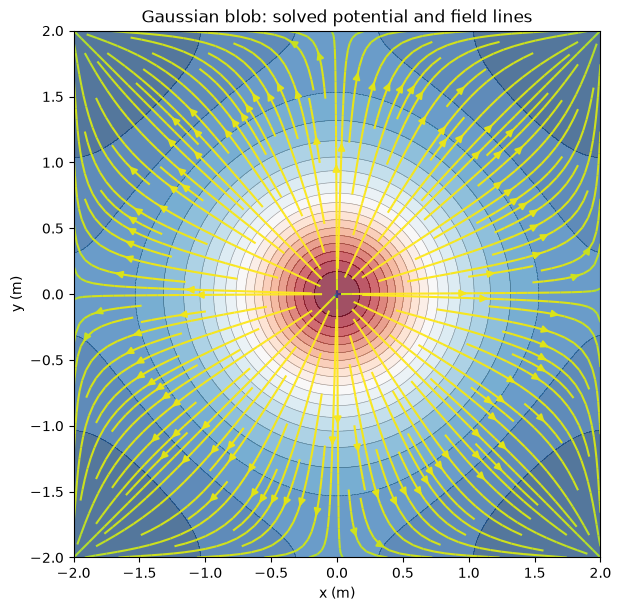

In [6]:
# the solved arrays already live on the plotting mesh (201 points over [-2, 2])
field_func = lambda xp, yp: (Ex, Ey)
potential_func = lambda xp, yp: Vg

fig, ax = eds.plot_field_and_potential(
    field_func, potential_func, extent=2.0, density=1.6, levels=20,
    title="Gaussian blob: solved potential and field lines",
)
fig, ax

## Exercises

1. **Plane waves as eigenfunctions.** In your own words, explain why $\nabla^2 e^{i\mathbf{k}\cdot\mathbf{r}} = -k^2 e^{i\mathbf{k}\cdot\mathbf{r}}$ turns the Poisson equation into an algebraic one in Fourier space, and why this makes the FFT solver cost $O(N \log N)$ instead of the $O(N^2)$ of a direct Green's-function sum.

2. **A different Fourier mode.** Repeat Worked example 1 with $\rho(x,y) = \rho_0 \sin(4\pi x)\sin(2\pi y)$. Derive the analytic solution (hint: the two directions now carry different wavenumbers, so $V = \rho/[\varepsilon_0(k_x^2 + k_y^2)]$) and confirm the solver reproduces it to machine precision.

3. **A periodic dipole.** On the $201\times201$ plot grid, build a source made of two Gaussian blobs of $+1\,\mathrm{nC}$ and $-1\,\mathrm{nC}$ separated along $x$, solve with `eds.poisson_solve`, and plot the result with `eds.plot_field_and_potential`. Where does the potential change sign, and how does the field-line pattern differ from the single blob?

4. **What if the source is not periodic?** The solver assumes the charge density repeats periodically outside the box. Predict what happens if you center the Gaussian blob near a corner of the box (so it is chopped off at the boundary), then test your prediction: solve and check the residual $-\varepsilon_0\nabla^2 V - \rho$ with `eds.laplacian`. Is the residual still small, and why does a small residual not guarantee a physical potential here?

5. **Gauss's law on the grid.** For the sinusoidal solution, compute the divergence of the recovered field with `np.gradient` ($\partial E_x/\partial x + \partial E_y/\partial y$, remembering the $[y,x]$ indexing) and compare it to $\rho/\varepsilon_0$. How does the mismatch scale with $N$, and does it match the $O(\Delta x^2)$ behavior seen in Worked example 4?

6. **Compare with the Green's function.** For a narrow blob ($\sigma = 0.1\,\mathrm{m}$, far from the box walls) the periodic solution should approach the free-space Coulomb form $V \approx Q/(4\pi\varepsilon_0 r)$ at moderate distances. Solve on the plot grid and plot a radial slice of $V(r)$ against $1/r$ to see where the approximation holds and where the box-size cutoff shows up.